# Análisis de quipus (khipus) en Python: ¿patrón o coincidencia?

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/crafter-research/khipu-null/blob/main/examples/quipu-analysis.ipynb)

Este notebook muestra cómo analizar quipus con Python usando datos públicos y [khipu-null](https://github.com/crafter-research/khipu-null), una herramienta de código abierto de [Crafter Research](https://crafter.ing).

Responde tres preguntas que aparecen en casi cualquier trabajo que compara quipus con un modelo:

1. ¿Qué quipus son compatibles con un modelo estructural, numérico o cromático?
2. ¿Cuáles son los cinco quipus que mejor lo representan, y esa selección es mejor que el azar?
3. ¿La correspondencia es una regularidad verificable o una coincidencia?

Quipu, khipu y kipu son grafías de lo mismo: los cordeles anudados con los que el Estado inca llevaba sus registros.

Datos: [Open Khipu Repository 2.1.0](https://doi.org/10.5281/zenodo.18025748) (licencia MIT). Método y resultados: [Colores y números en los khipus (quipus)](https://crafter.ing/es/research/khipu-colour-legend).

*English: a hands-on notebook to rank khipus (quipus) against a pattern and test whether a match is chance, with structure-preserving permutation nulls, a top-k test and Benjamini-Hochberg q-values.*

## 1. Instalar

In [1]:
import importlib.util
import subprocess
import sys

from importlib.metadata import PackageNotFoundError, version

def instalado(pkg):
    try:
        return version(pkg)
    except PackageNotFoundError:
        return None

kn = instalado("khipu-null")
if kn is None or tuple(map(int, kn.split(".")[:3])) < (0, 1, 2):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "khipu-null>=0.1.2"], check=True)
if importlib.util.find_spec("matplotlib") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib"], check=True)

import khipu_null
print("khipu-null", khipu_null.__version__)

khipu-null 0.1.2


## 2. Descargar el Open Khipu Repository

Un archivo SQLite con 619 quipus, 54.403 cuerdas y 110.677 nudos.

In [2]:
import urllib.request
from pathlib import Path

DB = Path("khipu.db")
if not DB.exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/khipulab/open-khipu-repository/v2.1.0/data/khipu.db", DB
    )
print(DB, round(DB.stat().st_size / 1e6, 1), "MB")

khipu.db 39.2 MB


## 3. Convertir a una tabla de cuerdas

Una fila por cuerda: quipu, grupo, posición, nivel (1 = colgante, 2+ = subsidiaria), color y valor. Un valor vacío significa que no hay nudos registrados: nunca se lee como cero.

`errata="confirmed"` aplica la lectura del Khipu Field Guide en KH0326, donde las dos fuentes difieren en el lugar decimal.

In [3]:
from khipu_null.corpus import import_okr, load

import_okr(DB, errata="confirmed").to_csv("cuerdas.csv", index=False)
cuerdas = load("cuerdas.csv")
print(cuerdas["khipu_id"].nunique(), "quipus,", len(cuerdas), "cuerdas")
cuerdas.head()

612 quipus, 54403 cuerdas


,khipu_id,cord_id,group_id,position,level,attachment,value,color
0,KH0001,3040649,1015898,1,1,V,13.0,BG:W
1,KH0001,3040745,1015902,1,2,U,110.0,W
2,KH0001,3040746,1015903,1,2,U,44.0,VR
3,KH0001,3040747,1015904,1,3,U,79.0,BG:W
4,KH0001,3040748,1015905,1,2,U,124.0,W


## 4. Explorar un quipu

In [4]:
colgantes = cuerdas[cuerdas["level"] == 1]
resumen = colgantes.groupby("khipu_id").agg(
    cuerdas=("cord_id", "size"),
    con_valor=("value", lambda v: v.notna().mean()),
    grupos=("group_id", "nunique"),
    colores=("color", "nunique"),
)
resumen.sort_values("cuerdas", ascending=False).head(10)

,cuerdas,con_valor,grupos,colores
khipu_id,,,,
KH0082,1650,0.167273,432,42
KH0468,864,0.261574,80,27
KH0242,570,0.538596,62,17
KH0068,557,0.289048,92,10
KH0240,472,0.709746,70,21
KH0034,415,0.359036,108,4
KH0237,406,0.438424,47,16
KH0428,395,0.860759,22,15
KH0128,339,0.463127,4,10


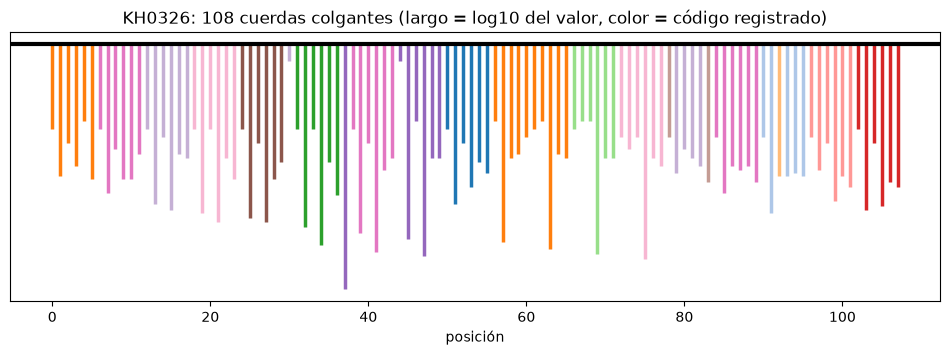

In [5]:
import matplotlib.pyplot as plt
import numpy as np

def dibujar(khipu_id):
    k = colgantes[colgantes["khipu_id"] == khipu_id].sort_values("position")
    codes = sorted(k["color"].fillna("?").unique())
    cmap = plt.get_cmap("tab20")
    paleta = {c: cmap(i % 20) for i, c in enumerate(codes)}
    fig, ax = plt.subplots(figsize=(12, 3.5))
    for x, (_, c) in enumerate(k.iterrows()):
        largo = np.log10(c["value"] + 1) if c["value"] == c["value"] else 0.15
        ax.vlines(x, 0, -largo, color=paleta[c["color"] if c["color"] == c["color"] else "?"], lw=2.5)
    ax.axhline(0, color="black", lw=3)
    ax.set_title(f"{khipu_id}: {len(k)} cuerdas colgantes (largo = log10 del valor, color = código registrado)")
    ax.set_yticks([])
    ax.set_xlabel("posición")
    plt.show()

dibujar("KH0326")

## 5. Escribir un patrón

Un patrón describe solo lo que tu modelo predice. Este ejemplo sale de los seis quipus del valle de Santa (Medrano y Urton 2018; Urton 2017, cap. 12): grupos de seis cuerdas cuya primera cuerda registra entre 0 y 13.

Es una prueba de cordura, no un descubrimiento: el patrón se escribió a partir de esos mismos quipus.

In [6]:
patron = {
    "name": "valle-de-santa",
    "level": 1,
    "min_cords": 30,
    "features": [
        {"type": "group_size", "size": 6},
        {"type": "first_cord_range", "size": 6, "min": 0, "max": 13},
    ],
    "null": {"draws": "auto", "seed": 0},
}

## 6. Ordenar los quipus y compararlos con el azar

Cada puntaje se compara con versiones del mismo quipu donde solo se permuta el campo que lee cada característica. Los grupos, posiciones y niveles nunca se mueven, así que la estructura del quipu no puede fabricar la coincidencia.

In [7]:
from khipu_null.rank import rank

res = rank(cuerdas, patron, top=6)
tabla, resumen_null = res["table"], res["summary"]
santa = {"KH0323", "KH0324", "KH0325", "KH0326", "KH0327", "KH0328"}
top = tabla.head(10).copy()
top["valle_de_santa"] = top["khipu_id"].isin(santa)
top[["rank", "khipu_id", "cords", "score", "null_mean", "p", "q", "valle_de_santa"]]

,rank,khipu_id,cords,score,null_mean,p,q,valle_de_santa
0,1,KH0324,54,1.000000,0.735345,0.002740,0.149772,True
1,2,KH0327,90,1.000000,0.880087,0.081279,1.000000,True
2,3,KH0109,66,1.000000,0.967370,0.588128,1.000000,False
3,4,KH0328,60,1.000000,1.000000,1.000000,1.000000,True
4,5,KH0325,206,0.995146,0.860947,0.000913,0.074886,True
5,6,KH0323,306,0.970588,0.938507,0.047489,0.851334,True
6,7,KH0384,96,0.968750,0.984946,0.931507,1.000000,False
7,8,KH0630,33,0.954545,0.954296,0.994521,1.000000,False
8,9,KH0488,62,0.935484,0.888829,0.478539,1.000000,False
9,10,KH0527,35,0.928571,0.907921,0.851142,1.000000,False


In [8]:
import json
print(json.dumps(resumen_null, indent=2, ensure_ascii=False, default=str))

{
  "khipus": 328,
  "draws": 1094,
  "min_attainable_p": 0.0009132420091324201,
  "tested_features": {
    "first_cord_range": "value:within_khipu"
  },
  "untested_features": [
    "group_size"
  ],
  "top": 6,
  "top_mean_score": 0.9942889777270132,
  "null_top_mean_95": [
    0.9541271295908393,
    0.9857007575757576
  ],
  "top_p": 0.0009132420091324201,
  "significant_at_q05": 0
}


## 7. Cómo leer el resultado

- **p**: qué tan raro es el puntaje de ese quipu bajo su propio nulo (permutación, una cola).
- **q**: el p corregido por haber probado cientos de quipus (Benjamini-Hochberg). Es el número que importa para un quipu individual.
- **Prueba top-k**: compara el promedio de tus k mejores con los k mejores que saldrían de versiones nulas de cada quipu. Es la respuesta honesta a "¿estos cinco son especiales, o cualquier cinco se verían así de bien?".

Lo que no prueba: un p bajo dice que la coincidencia es improbable bajo ese nulo. No dice qué significa el quipu.

## 8. Tu propio patrón

Parte de [`examples/template.yaml`](https://github.com/crafter-research/khipu-null/blob/main/examples/template.yaml) y deja solo las características que tu modelo predice:

| Característica | Pregunta |
|---|---|
| `group_size` | ¿Los grupos están hechos de unidades de este tamaño? |
| `first_cord_range` | ¿La primera cuerda de cada tramo cae en [min, max] más que una cuerda al azar? |
| `group_sum` | ¿La primera (o última) cuerda es la suma de las demás? |
| `color_repeat` | ¿Los colores se repiten con este periodo? |
| `attachment_split` | ¿Las primeras cuerdas de cada tramo se amarran con este código más que al azar? |
| `value_range` | ¿Qué proporción de valores cae en [min, max]? |

Para buscar, por ejemplo, bloques cuya cuerda inicial es la suma del resto:

In [9]:
mi_patron = {
    "name": "sumas-por-grupo",
    "level": 1,
    "min_cords": 20,
    "features": [{"type": "group_sum", "sum_position": "first"}],
    "null": {"draws": 200, "seed": 0},
}
rank(cuerdas, mi_patron, top=5)["table"].head(5)[["rank", "khipu_id", "cords", "score", "null_mean", "p", "q"]]

,rank,khipu_id,cords,score,null_mean,p,q
0,1,KH0592,60,1.000000,0.325581,0.340909,1.000000
1,2,KH0491,86,0.833333,0.029705,0.004975,0.206744
2,3,KH0503,82,0.652174,0.024876,0.004975,0.206744
3,4,KH0504,103,0.521739,0.016364,0.004975,0.206744
4,5,KH0198,41,0.500000,0.010101,0.025126,0.552764


## 9. CSV con columnas en español

Si tu tabla de quipus viene con columnas en español (una fila por cuerda colgante), renómbralas así y usa el mismo flujo:

```python
import pandas as pd
d = pd.read_csv("quipus.csv", encoding="utf-8-sig", dtype=str)
cols = {"codigo_kh": "khipu_id", "cuerda_uid": "cord_id", "grupo_uid": "group_id",
        "posicion": "position", "nivel": "level", "color": "color", "valor": "value"}
d[list(cols)].rename(columns=cols).to_csv("cords.csv", index=False)
```

O desde la terminal: `uvx khipu-null rank cords.csv mi-patron.yaml -o out --top 5`.

## Referencias

- Crafter Research (2026). [Colores y números en los khipus (quipus): una medición, una auditoría de datos y una herramienta](https://crafter.ing/es/research/khipu-colour-legend). [English](https://crafter.ing/research/khipu-colour-legend).
- [khipu-null](https://github.com/crafter-research/khipu-null) · [PyPI](https://pypi.org/project/khipu-null/) · MIT.
- [Open Khipu Repository 2.1.0](https://doi.org/10.5281/zenodo.18025748).
- Medrano, M. y Urton, G. (2018). Toward the Decipherment of a Set of Mid-Colonial Khipus from the Santa Valley, Coastal Peru. *Ethnohistory* 65(1).

Si usas este notebook o khipu-null, cita: Crafter Research (2026), khipu-null, https://github.com/crafter-research/khipu-null